## Problem description

We select exactly 50% of the nodes (rounded up if odd) and form a Hamiltonian cycle minimizing the sum of edge lengths plus selected node costs. Distances are Euclidean, rounded to integers. Methods use only the distance matrix and node costs after the instance is loaded.


## Helpers and parameters

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

DATA = Path('data')
INSTANCES = ['TSPA', 'TSPB']
RNG_SEED = 0
NUM_OF_RANDOM_RUNS = 200

# weights for the weighted-sum criterion (regret, -best_delta)
WEIGHT_CONFIGS = [
    (1.0, 1.0),   # default: equal weights
    (1.0, 0.5),
    (0.5, 1.0),
]

def load_instance(name: str):
    d = np.loadtxt(DATA / f'{name}.csv', delimiter=';', skiprows=1, dtype=int)
    xy, costs = d[:, :2], d[:, 2]
    diff = xy[:, None, :] - xy[None, :, :]
    dist = np.rint(np.sqrt((diff ** 2).sum(axis=-1))).astype(int)
    n = len(costs)
    k = (n + 1) // 2
    return {'name': name, 'xy': xy, 'costs': costs, 'dist': dist, 'n': n, 'k': k}

problems = {name: load_instance(name) for name in INSTANCES}

def compute_cost(tour, dist: np.ndarray, costs: np.ndarray) -> int:
    t = np.asarray(tour, dtype=int)
    return int(dist[t, np.roll(t, -1)].sum() + costs[t].sum())

def check_solution(tour, n: int, k: int) -> tuple[bool, str]:
    """Used at the end to check solution's correctness"""
    t = list(tour)
    if len(t) != k:
        return False, f'length {len(t)} != k={k}'
    if len(set(t)) != k:
        return False, 'duplicate nodes'
    if any(not isinstance(v, (int, np.integer)) or v < 0 or v >= n for v in t):
        return False, 'index out of range'
    return True, 'ok'

problem = problems['TSPA']
print({n: (problems[n]['n'], problems[n]['k']) for n in INSTANCES})


{'TSPA': (200, 100), 'TSPB': (200, 100)}


## Pseudocode

### Path insertion deltas (extended NN)

For a partial path `T = (t0, …, t_{m-1})` and candidate `c`:
- insert at start: `Δ = d(c, t0) + cost(c)`
- insert at end: `Δ = d(t_{m-1}, c) + cost(c)`
- insert between `t_j` and `t_{j+1}`: `Δ = d(t_j, c) + d(c, t_{j+1}) - d(t_j, t_{j+1}) + cost(c)`

### Cycle insertion deltas (greedy cycle)

For a partial cycle on `T` and candidate `c`:
- if `|T| = 1`: `Δ = 2·d(t0, c) + cost(c)`
- else, insert on edge `(t_j, t_{j+1})`: `Δ = d(t_j, c) + d(c, t_{j+1}) - d(t_j, t_{j+1}) + cost(c)`

### Greedy 2-regret

```
T ← [start]
while |T| < k:
    for each unused candidate c:
        compute insertion Δ over all feasible positions
        regret(c) ← 2nd_best(Δ) − best(Δ)   # 0 if only one position
    pick c* with maximum regret (tie-break: smaller best Δ)
    insert c* at its best position
return T as a cycle (path methods close via objective evaluation)
```

### Weighted sum (2-regret + best change)

Same loop, but select `c*` maximizing:

`score(c) = w_regret · regret(c) − w_cost · best(Δ(c))`

Default: `w_regret = w_cost = 1`. Pure greedy best-change is the special case `w_regret = 0`.


## Search method definitions

Lab 1 baselines are kept for comparison. New methods: 2-regret and weighted-sum, each on path (extended NN) and cycle insertion.


In [2]:
def random_tour(n: int, k: int, rng: np.random.Generator) -> list[int]:
    selected = rng.choice(n, size=k, replace=False)
    rng.shuffle(selected)
    return [int(v) for v in selected]


def nearest_neighbor_at_end(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        last = tour[-1]
        cand = np.flatnonzero(~used)
        vals = distances[last, cand] + costs[cand]
        nxt = int(cand[int(np.argmin(vals))])
        tour.append(nxt); used[nxt] = True
    return tour


def nearest_neighbor_anywhere(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int); m = len(t)
        D = distances[np.ix_(cand, t)]
        best = D[:, 0].astype(np.int64).copy()
        pos = np.zeros(len(cand), dtype=int)
        d_end = D[:, -1]
        upd = d_end < best; best[upd] = d_end[upd]; pos[upd] = m
        if m > 1:
            seg = distances[t[:-1], t[1:]]
            ins = D[:, :-1] + D[:, 1:] - seg[None, :]
            j = np.argmin(ins, axis=1)
            v = ins[np.arange(len(cand)), j]
            upd = v < best; best[upd] = v[upd]; pos[upd] = j[upd] + 1
        best = best + costs[cand]
        i = int(np.argmin(best))
        tour.insert(int(pos[i]), int(cand[i])); used[cand[i]] = True
    return tour


def greedy_cycle(start: int, dist: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int); m = len(t)
        if m == 1:
            delta = 2 * dist[int(start), cand] + costs[cand]
            i = int(np.argmin(delta))
            tour.append(int(cand[i])); used[cand[i]] = True
            continue
        nxt = np.roll(t, -1)
        seg = dist[t, nxt]
        ins = dist[np.ix_(cand, t)] + dist[np.ix_(cand, nxt)] - seg[None, :]
        j = np.argmin(ins, axis=1)
        v = ins[np.arange(len(cand)), j] + costs[cand]
        i = int(np.argmin(v))
        tour.insert(int(j[i]) + 1, int(cand[i])); used[cand[i]] = True
    return tour


def _path_insertion_deltas(cand: np.ndarray, t: np.ndarray, distances: np.ndarray) -> np.ndarray:
    m = len(t)
    D = distances[np.ix_(cand, t)]
    deltas = np.empty((len(cand), m + 1), dtype=np.int64)
    deltas[:, 0] = D[:, 0]
    deltas[:, m] = D[:, -1]
    if m > 1:
        seg = distances[t[:-1], t[1:]]
        deltas[:, 1:m] = D[:, :-1] + D[:, 1:] - seg[None, :]
    return deltas


def _cycle_insertion_deltas(cand: np.ndarray, t: np.ndarray, dist: np.ndarray) -> np.ndarray:
    if len(t) == 1:
        return (2 * dist[int(t[0]), cand])[:, None]
    nxt = np.roll(t, -1)
    seg = dist[t, nxt]
    return dist[np.ix_(cand, t)] + dist[np.ix_(cand, nxt)] - seg[None, :]


def _choose_candidate(deltas: np.ndarray, costs_cand: np.ndarray, mode: str,
                      w_regret: float, w_cost: float) -> tuple[int, int]:
    d = deltas + costs_cand[:, None]
    if d.shape[1] == 1:
        best = d[:, 0]
        regret = np.zeros(len(costs_cand), dtype=np.float64)
        best_pos = np.zeros(len(costs_cand), dtype=int)
    else:
        best_pos = np.argmin(d, axis=1)
        best = d[np.arange(len(d)), best_pos]
        part = np.argpartition(d, 1, axis=1)[:, :2]
        v0 = d[np.arange(len(d)), part[:, 0]]
        v1 = d[np.arange(len(d)), part[:, 1]]
        second = np.maximum(v0, v1)
        regret = (second - best).astype(np.float64)

    if mode == 'regret':
        # maximize regret, then minimize best Δ
        i = int(np.lexsort((best, -regret))[0])
    else:
        score = w_regret * regret - w_cost * best.astype(np.float64)
        i = int(np.lexsort((best, -score))[0])
    return i, int(best_pos[i])


def greedy_2regret_nn(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """2-regret construction using path (extended NN) insertion."""
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(_path_insertion_deltas(cand, t, distances), costs[cand], 'regret', 1.0, 1.0)
        tour.insert(pos, int(cand[i])); used[cand[i]] = True
    return tour


def greedy_2regret_cycle(start: int, dist: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """2-regret construction using cycle insertion."""
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(_cycle_insertion_deltas(cand, t, dist), costs[cand], 'regret', 1.0, 1.0)
        if len(tour) == 1:
            tour.append(int(cand[i]))
        else:
            tour.insert(pos + 1, int(cand[i]))
        used[cand[i]] = True
    return tour


def greedy_weighted_nn(start: int, distances: np.ndarray, costs: np.ndarray, k: int,
                       w_regret: float = 1.0, w_cost: float = 1.0) -> list[int]:
    """Weighted 2-regret + best Δ using path (extended NN) insertion."""
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(
            _path_insertion_deltas(cand, t, distances), costs[cand], 'weighted', w_regret, w_cost)
        tour.insert(pos, int(cand[i])); used[cand[i]] = True
    return tour


def greedy_weighted_cycle(start: int, dist: np.ndarray, costs: np.ndarray, k: int,
                          w_regret: float = 1.0, w_cost: float = 1.0) -> list[int]:
    """Weighted 2-regret + best Δ using cycle insertion."""
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(
            _cycle_insertion_deltas(cand, t, dist), costs[cand], 'weighted', w_regret, w_cost)
        if len(tour) == 1:
            tour.append(int(cand[i]))
        else:
            tour.insert(pos + 1, int(cand[i]))
        used[cand[i]] = True
    return tour


## Smoke check

In [3]:
rng = np.random.default_rng(RNG_SEED)
smoke_fns = [
    ('random', lambda s, D, C, k: random_tour(problem['n'], problem['k'], rng)),
    ('nearest_neighbor_at_end', nearest_neighbor_at_end),
    ('nearest_neighbor_anywhere', nearest_neighbor_anywhere),
    ('greedy_cycle', greedy_cycle),
    ('greedy_2regret_nn', greedy_2regret_nn),
    ('greedy_2regret_cycle', greedy_2regret_cycle),
    ('greedy_weighted_nn', greedy_weighted_nn),
    ('greedy_weighted_cycle', greedy_weighted_cycle),
]
for name, fn in smoke_fns:
    tt = fn(0, problem['dist'], problem['costs'], problem['k'])
    ok, msg = check_solution(tt, problem['n'], problem['k'])
    print(f'{name}: cost={compute_cost(tt, problem["dist"], problem["costs"])} check={ok} ({msg})')


random: cost=264621 check=True (ok)
nearest_neighbor_at_end: cost=84780 check=True (ok)
nearest_neighbor_anywhere: cost=73503 check=True (ok)
greedy_cycle: cost=71488 check=True (ok)
greedy_2regret_nn: cost=117387 check=True (ok)
greedy_2regret_cycle: cost=109845 check=True (ok)
greedy_weighted_nn: cost=70594 check=True (ok)
greedy_weighted_cycle: cost=71108 check=True (ok)


## Computational experiment

Each constructive method is run from every start node. Random: 200 solutions. Weighted-sum methods use equal weights in the main comparison; additional weight settings are reported separately.


In [4]:
BASELINE_METHODS = [
    ('nearest_neighbor_at_end', nearest_neighbor_at_end),
    ('nearest_neighbor_anywhere', nearest_neighbor_anywhere),
    ('greedy_cycle', greedy_cycle),
]
REGRET_METHODS = [
    ('greedy_2regret_nn', greedy_2regret_nn),
    ('greedy_2regret_cycle', greedy_2regret_cycle),
    ('greedy_weighted_nn', greedy_weighted_nn),
    ('greedy_weighted_cycle', greedy_weighted_cycle),
]
ALL_MAIN_METHODS = (
    ['random']
    + [n for n, _ in BASELINE_METHODS]
    + [n for n, _ in REGRET_METHODS]
)

results, best_tours, timings = {}, {}, {}
rng = np.random.default_rng(RNG_SEED)

for name in INSTANCES:
    pr = problems[name]
    n, k, dist, costs = pr['n'], pr['k'], pr['dist'], pr['costs']
    results[name], best_tours[name], timings[name] = {}, {}, {}

    t0 = time.perf_counter()
    tours = [random_tour(n, k, rng) for _ in range(NUM_OF_RANDOM_RUNS)]
    vals = np.array([compute_cost(t, dist, costs) for t in tours])
    results[name]['random'] = vals
    best_tours[name]['random'] = tours[int(np.argmin(vals))]
    timings[name]['random'] = time.perf_counter() - t0

    for mname, fn in BASELINE_METHODS + REGRET_METHODS:
        t0 = time.perf_counter()
        tours = [fn(s, dist, costs, k) for s in range(n)]
        vals = np.array([compute_cost(t, dist, costs) for t in tours])
        results[name][mname] = vals
        best_tours[name][mname] = tours[int(np.argmin(vals))]
        timings[name][mname] = time.perf_counter() - t0
        print(f'{name}/{mname}: min={vals.min()} max={vals.max()} mean={vals.mean():.1f} ({timings[name][mname]:.2f}s)')

    print(f"{name}/random: min={results[name]['random'].min()} max={results[name]['random'].max()} "
          f"mean={results[name]['random'].mean():.1f} ({timings[name]['random']:.2f}s)")


TSPA/nearest_neighbor_at_end: min=83182 max=89433 mean=85108.5 (0.04s)


TSPA/nearest_neighbor_anywhere: min=71179 max=75450 mean=73178.4 (0.82s)


TSPA/greedy_cycle: min=71488 max=74410 mean=72636.0 (1.21s)


TSPA/greedy_2regret_nn: min=106373 max=126570 mean=116659.0 (1.20s)


TSPA/greedy_2regret_cycle: min=107434 max=123428 mean=115468.5 (1.64s)


...

TSPB/greedy_cycle: min=49001 max=57324 mean=51400.6 (1.22s)


TSPB/greedy_2regret_nn: min=67121 max=79013 mean=73646.8 (1.20s)


TSPB/greedy_2regret_cycle: min=66505 max=77254 mean=72530.5 (1.63s)


TSPB/greedy_weighted_nn: min=44891 max=55247 mean=47653.8 (1.21s)


TSPB/greedy_weighted_cycle: min=47144 max=55700 mean=50984.5 (1.62s)
TSPB/random: min=190279 max=238119 mean=213699.6 (0.00s)


### Weight sensitivity (weighted-sum methods)

In [5]:
weight_results = []
for name in INSTANCES:
    pr = problems[name]
    n, k, dist, costs = pr['n'], pr['k'], pr['dist'], pr['costs']
    for w_r, w_c in WEIGHT_CONFIGS:
        for base, fn in [('nn', greedy_weighted_nn), ('cycle', greedy_weighted_cycle)]:
            tours = [fn(s, dist, costs, k, w_regret=w_r, w_cost=w_c) for s in range(n)]
            vals = np.array([compute_cost(t, dist, costs) for t in tours])
            weight_results.append({
                'instance': name,
                'base': base,
                'w_regret': w_r,
                'w_cost': w_c,
                'min_cost': int(vals.min()),
                'max_cost': int(vals.max()),
                'mean_cost': float(vals.mean()),
            })
            print(f'{name}/weighted_{base} w=({w_r},{w_c}): min={vals.min()} mean={vals.mean():.1f}')

weight_summary = pd.DataFrame(weight_results).set_index(['instance', 'base', 'w_regret', 'w_cost'])
weight_summary


TSPA/weighted_nn w=(1.0,1.0): min=70010 mean=72401.3


TSPA/weighted_cycle w=(1.0,1.0): min=71108 mean=72135.2


TSPA/weighted_nn w=(1.0,0.5): min=71271 mean=73567.7


TSPA/weighted_cycle w=(1.0,0.5): min=70629 mean=72194.5


TSPA/weighted_nn w=(0.5,1.0): min=71091 mean=72895.4


...

TSPB/weighted_nn w=(1.0,0.5): min=46112 mean=49588.8


TSPB/weighted_cycle w=(1.0,0.5): min=49661 mean=51807.3


TSPB/weighted_nn w=(0.5,1.0): min=44504 mean=48714.3


TSPB/weighted_cycle w=(0.5,1.0): min=48962 mean=51017.7


min_cost  max_cost  mean_cost
instance base  w_regret w_cost                               
TSPA     nn    1.0      1.0        70010     75452  72401.335
         cycle 1.0      1.0        71108     73395  72135.230
         nn    1.0      0.5        71271     77610  73567.685
         cycle 1.0      0.5        70629     74322  72194.480
         nn    0.5      1.0        71091     75246  72895.410
         cycle 0.5      1.0        71424     73912  72483.675
TSPB     nn    1.0      1.0        44891     55247  47653.785
         cycle 1.0      1.0        47144     55700  50984.485
         nn    1.0      0.5        46112     58755  49588.815
         cycle 1.0      0.5        49661     58236  51807.320
         nn    0.5      1.0        44504     57057  48714.330
         cycle 0.5      1.0        48962     54192  51017.725

## Summary of results (including Lab 1 methods)

In [6]:
rows = []
for name in INSTANCES:
    for mname in ALL_MAIN_METHODS:
        v = results[name][mname]
        rows.append({
            'instance': name,
            'method': mname,
            'min_cost': int(v.min()),
            'max_cost': int(v.max()),
            'mean_cost': float(v.mean()),
            'time_s': round(timings[name][mname], 2),
        })
summary = pd.DataFrame(rows).set_index(['instance', 'method'])
summary


min_cost  max_cost   mean_cost  time_s
instance method                                                           
TSPA     random                       234051    297098  262602.880    0.00
         nearest_neighbor_at_end       83182     89433   85108.510    0.04
         nearest_neighbor_anywhere     71179     75450   73178.435    0.82
         greedy_cycle                  71488     74410   72635.975    1.21
         greedy_2regret_nn            106373    126570  116659.005    1.20
         greedy_2regret_cycle         107434    123428  115468.505    1.64
         greedy_weighted_nn            70010     75452   72401.335    1.22
         greedy_weighted_cycle         71108     73395   72135.230    1.62
TSPB     random                       190279    238119  213699.650    0.00
         nearest_neighbor_at_end       52319     59030   54390.430    0.04
         nearest_neighbor_anywhere     44417     53438   45870.255    0.83
         greedy_cycle                  49001     57324   51400.595    1.22
         greedy_2regret_nn             67121     79013   73646.815    1.20
         greedy_2regret_cycle          66505     77254   72530.480    1.63
         greedy_weighted_nn            44891     55247   47653.785    1.21
         greedy_weighted_cycle         47144     55700   50984.485    1.62

## Best-solution visualizations

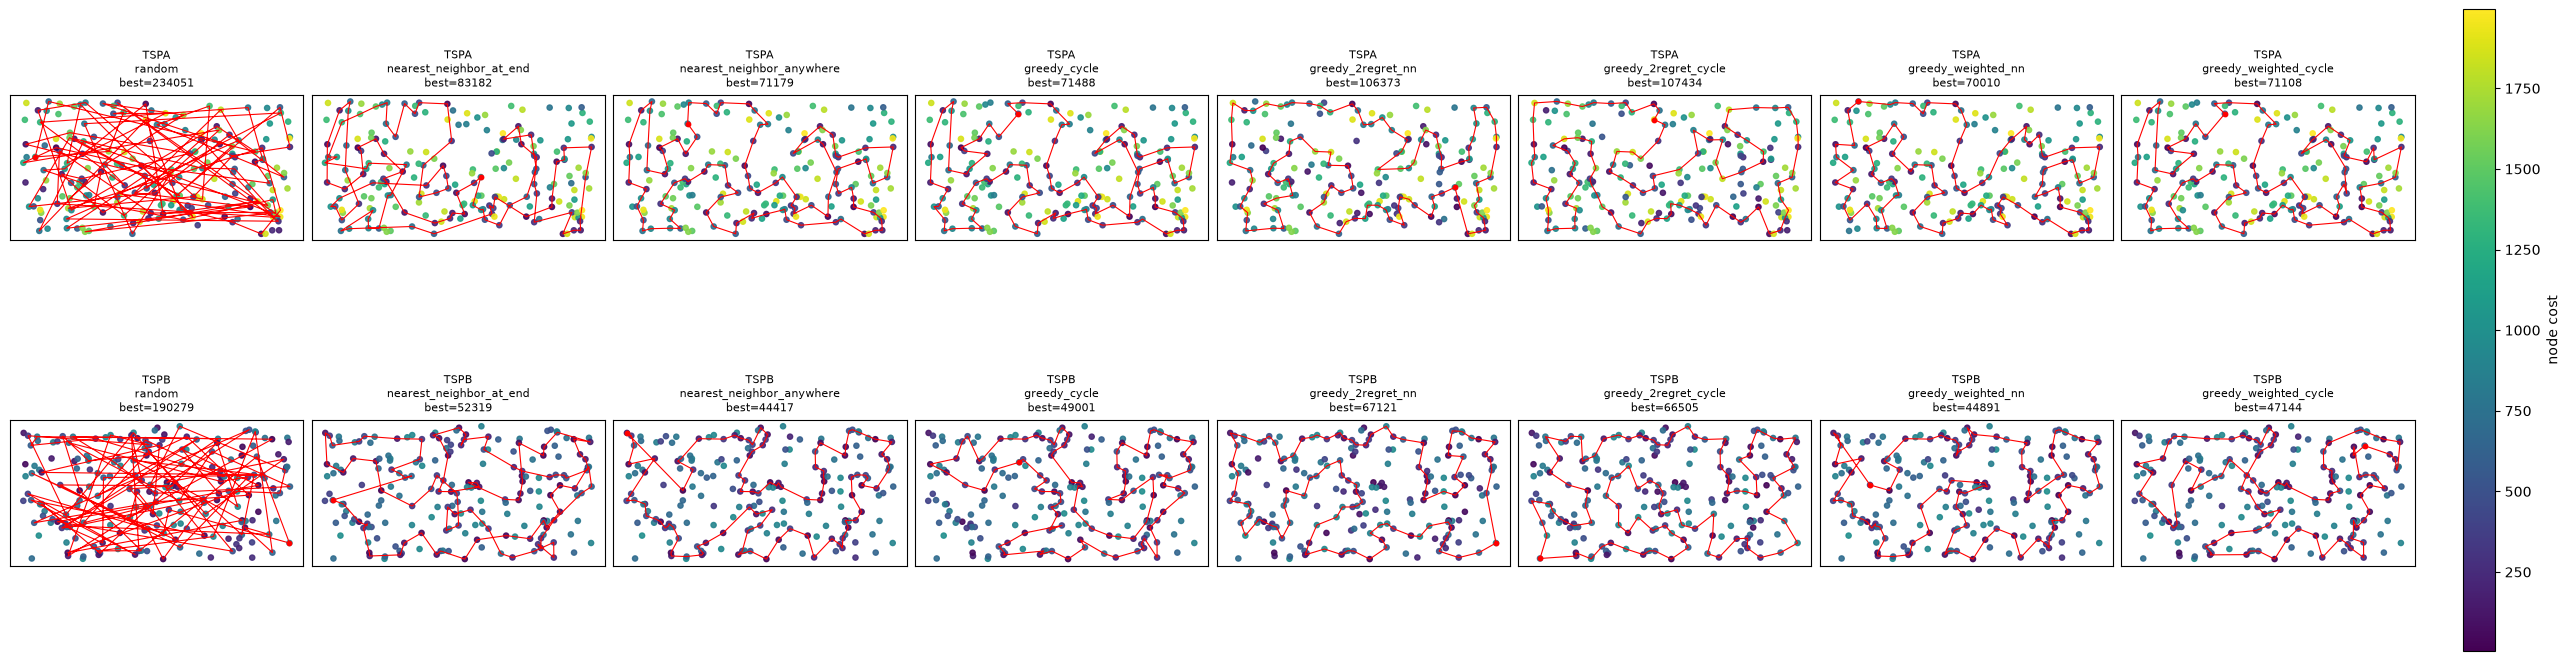

In [7]:
PLOT_METHODS = ALL_MAIN_METHODS
ncols = 4
nrows = len(INSTANCES) * ((len(PLOT_METHODS) + ncols - 1) // ncols)

all_costs = np.concatenate([problems[n]['costs'] for n in INSTANCES])
norm = Normalize(vmin=int(all_costs.min()), vmax=int(all_costs.max()))
sm = plt.cm.ScalarMappable(norm=norm, cmap='viridis')

with plt.style.context('default'):
    fig, axes = plt.subplots(len(INSTANCES), len(PLOT_METHODS), figsize=(3.2 * len(PLOT_METHODS), 6.5),
                             constrained_layout=True)
    fig.patch.set_facecolor('white')
    if len(INSTANCES) == 1:
        axes = np.array([axes])
    for i, name in enumerate(INSTANCES):
        pr = problems[name]
        xy, costs = pr['xy'], pr['costs']
        for j, mname in enumerate(PLOT_METHODS):
            ax = axes[i, j]
            ax.set_facecolor('white')
            tour = best_tours[name][mname]
            t = np.asarray(tour, dtype=int)
            c = compute_cost(t, pr['dist'], pr['costs'])
            ax.scatter(xy[:, 0], xy[:, 1], c=costs, cmap='viridis', norm=norm, s=14, alpha=0.9, zorder=1)
            path = xy[np.append(t, t[0])]
            ax.plot(path[:, 0], path[:, 1], 'r-', lw=0.8, zorder=3)
            ax.scatter(path[0, 0], path[0, 1], c='red', s=10, zorder=4)
            ax.set_title(f'{name}\n{mname}\nbest={c}', fontsize=8)
            ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sm, ax=axes, location='right', fraction=0.015, pad=0.02, label='node cost')
    plt.show()


## Final paths

Best node-index lists per instance/method, with solution-checker status.


In [8]:
for name in INSTANCES:
    pr = problems[name]
    print(f'=== {name} (n={pr["n"]}, k={pr["k"]}) ===')
    for mname in ALL_MAIN_METHODS:
        tour = best_tours[name][mname]
        cost = compute_cost(tour, pr['dist'], pr['costs'])
        ok, msg = check_solution(tour, pr['n'], pr['k'])
        print(f'{mname}:')
        print(f'cost={cost}  checker={ok} ({msg})')
        print('node indices:', tour)
        print()


=== TSPA (n=200, k=100) ===
random:
cost=234051  checker=True (ok)
node indices: [195, 108, 8, 144, 35, 18, 93, 74, 11, 165, 188, 16, 44, 26, 76, 10, 198, 31, 180, 41, 184, 13, 9, 79, 80, 4, 78, 133, 132, 138, 45, 50, 143, 113, 84, 24, 59, 166, 86, 157, 85, 156, 168, 53, 183, 5, 181, 105, 194, 155, 103, 193, 130, 70, 68, 58, 49, 123, 42, 116, 148, 110, 22, 38, 52, 167, 139, 19, 51, 191, 30, 63, 14, 81, 23, 73, 87, 152, 178, 90, 164, 189, 32, 117, 64, 118, 151, 199, 21, 40, 185, 196, 176, 150, 140, 96, 83, 0, 153, 60]

nearest_neighbor_at_end:
cost=83182  checker=True (ok)
node indices: [124, 94, 63, 53, 180, 154, 135, 123, 65, 116, 59, 115, 139, 193, 41, 42, 160, 34, 22, 18, 108, 69, 159, 181, 184, 177, 54, 30, 48, 43, 151, 176, 80, 79, 133, 162, 51, 137, 183, 143, 0, 117, 46, 68, 93, 140, 36, 163, 199, 146, 195, 103, 5, 96, 118, 149, 131, 112, 4, 84, 35, 10, 190, 127, 70, 101, 97, 1, 152, 120, 78, 145, 185, 40, 165, 90, 81, 113, 175, 171, 16, 31, 44, 92, 57, 106, 49, 144, 62, 14, 178,

## Conclusions

- Pure **2-regret** forces insertions that would otherwise be deferred; on these instances it is typically weaker than best-change greedy, because high-regret nodes can still have large absolute insertion cost.
- The **weighted sum** (equal weights) combines urgency (regret) with immediate objective change and usually improves on — or stays close to — the Lab 1 extended NN / greedy cycle baselines.
- **Cycle** insertion remains a strong base; path (extended NN) insertion with weighting is competitive and sometimes better depending on the instance.
- Weight sensitivity: increasing the cost weight relative to regret tends to move results toward classical greedy; increasing the regret weight emphasizes diversification of insertions. Equal weights are a solid default.
- All reported best solutions pass the solution checker (length `k`, unique nodes in range).
